In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib
import os

print("SHAP version:", shap.__version__)
print("Libraries imported successfully.")

SHAP version: 0.52.0
Libraries imported successfully.


d:\Explainable-AI-CDSS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# ============================================================
# CELL 2 — DEFINE PATHS
# ============================================================

BASE_DIR = os.path.abspath(
    os.path.join(os.getcwd(), "..")
)

PROCESSED_DIR = os.path.join(
    BASE_DIR,
    "datasets",
    "processed",
    "stroke"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "models",
    "stroke"
)

print("Processed directory:", PROCESSED_DIR)
print("Model directory:", MODEL_DIR)

Processed directory: d:\Explainable-AI-CDSS\datasets\processed\stroke
Model directory: d:\Explainable-AI-CDSS\models\stroke


In [5]:
# ============================================================
# CELL 3 — LOAD PROCESSED DATA
# ============================================================

X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_train.csv")
)

X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "x_test.csv")
)

y_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_train.csv")
).squeeze()

y_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "y_test.csv")
).squeeze()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (4088, 21)
X_test shape: (1022, 21)
y_train shape: (4088,)
y_test shape: (1022,)


In [6]:
# ============================================================
# CELL 4 — LOAD MODEL AND PREPROCESSING ARTIFACTS
# ============================================================

model = joblib.load(
    os.path.join(MODEL_DIR, "best_model.pkl")
)

scaler = joblib.load(
    os.path.join(MODEL_DIR, "scaler.pkl")
)

feature_names = joblib.load(
    os.path.join(MODEL_DIR, "feature_names.pkl")
)

print("Model:", type(model).__name__)
print("Number of features:", len(feature_names))
print("Features:")
print(feature_names)

Model: LogisticRegression
Number of features: 21
Features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


In [7]:
# ============================================================
# CELL 5 — VERIFY FEATURE NAMES
# ============================================================

print("X_train columns:")
print(X_train.columns.tolist())

print("\nSaved feature names:")
print(feature_names)

print(
    "\nFeature names match:",
    X_train.columns.tolist() == list(feature_names)
)

X_train columns:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Saved feature names:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Feature names match: True


In [8]:
# ============================================================
# CELL 6 — CREATE SHAP EXPLAINER
# ============================================================

explainer = shap.LinearExplainer(
    model,
    X_train
)

print("SHAP LinearExplainer created successfully.")

Background dataset has 4088 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4088 when initializing the masker.


SHAP LinearExplainer created successfully.


In [9]:
# ============================================================
# CELL 7 — GENERATE SHAP VALUES
# ============================================================

shap_values = explainer(X_test)

print("SHAP values generated successfully.")
print("SHAP values shape:", shap_values.values.shape)

SHAP values generated successfully.
SHAP values shape: (1022, 21)


In [10]:
# ============================================================
# CELL 8 — INSPECT SHAP OUTPUT
# ============================================================

print("Number of test samples:", shap_values.values.shape[0])
print("Number of features:", shap_values.values.shape[1])

print("\nFirst patient's SHAP values:")
print(shap_values.values[0])

Number of test samples: 1022
Number of features: 21

First patient's SHAP values:
[ 1.47169497e+00 -9.55671231e-02 -9.23792195e-03 -1.30362746e-01
  4.14233841e-02 -3.96242048e-02 -3.74241698e-02  1.02390599e-18
 -2.53948330e-02 -2.53948330e-02  1.98881892e-02  1.38746656e-17
 -5.37415556e-02  5.07831081e-02 -1.58807490e-01 -4.32583423e-02
 -4.32583423e-02  1.02833029e-02 -2.44142404e-02 -1.22444900e-01
 -3.26100285e-02]


In [11]:
# ============================================================
# CELL 9 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_importance)

,Feature,Mean_Absolute_SHAP
0,age,1.608977e+00
1,work_type_children,2.322892e-01
2,avg_glucose_level,1.487737e-01
3,hypertension,1.357062e-01
4,smoking_status_never smoked,9.724505e-02
5,work_type_Self-employed,8.962644e-02
6,smoking_status_smokes,6.948993e-02
7,work_type_Private,5.766483e-02
8,Residence_type_Urban,3.777958e-02
9,Residence_type_Rural,3.777958e-02


In [12]:
# ============================================================
# CELL 10 — TOP 15 SHAP FEATURES
# ============================================================

top_features = shap_importance.head(15)

display(top_features)

,Feature,Mean_Absolute_SHAP
0,age,1.608977
1,work_type_children,0.232289
2,avg_glucose_level,0.148774
3,hypertension,0.135706
4,smoking_status_never smoked,0.097245
5,work_type_Self-employed,0.089626
6,smoking_status_smokes,0.069490
7,work_type_Private,0.057665
8,Residence_type_Urban,0.037780
9,Residence_type_Rural,0.037780


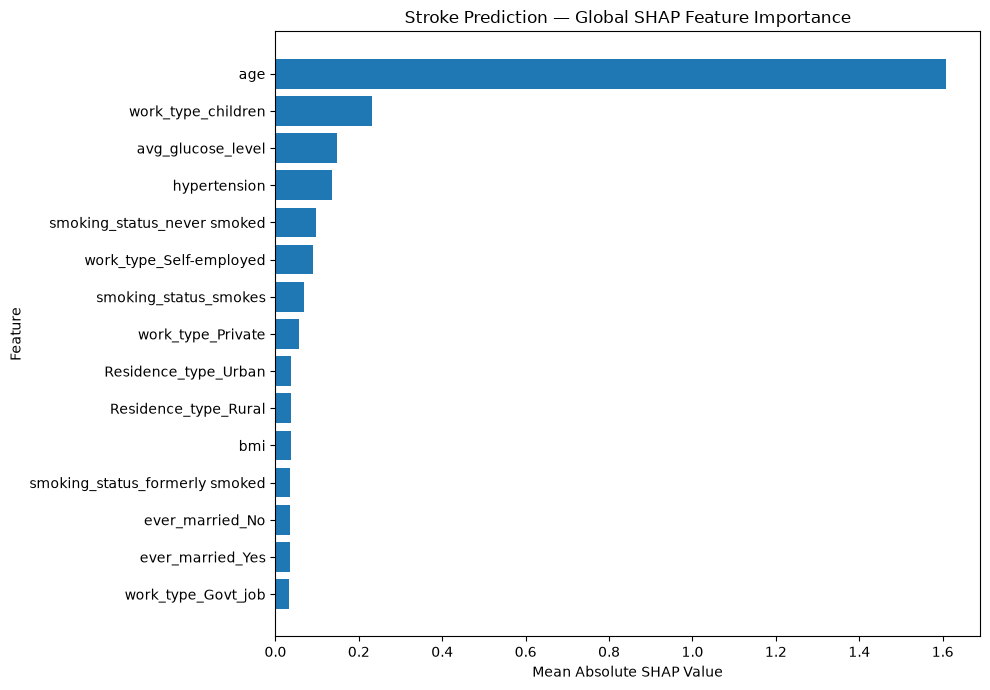

In [13]:
# ============================================================
# CELL 11 — GLOBAL SHAP FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Stroke Prediction — Global SHAP Feature Importance")

plt.tight_layout()
plt.show()

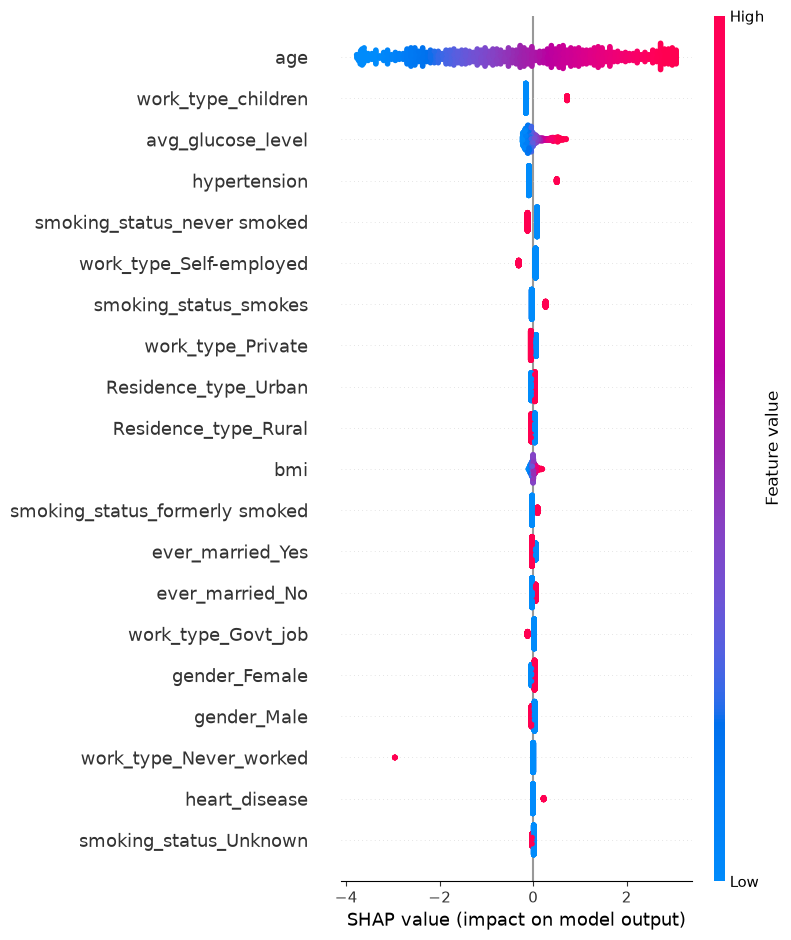

In [14]:
# ============================================================
# CELL 12 — SHAP SUMMARY PLOT
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_test,
    feature_names=feature_names
)

In [15]:
# ============================================================
# CELL 13 — SAVE SHAP FEATURE IMPORTANCE
# ============================================================

output_path = os.path.join(
    PROCESSED_DIR,
    "shap_feature_importance.csv"
)

shap_importance.to_csv(
    output_path,
    index=False
)

print("SHAP feature importance saved successfully.")
print("Saved to:", output_path)

SHAP feature importance saved successfully.
Saved to: d:\Explainable-AI-CDSS\datasets\processed\stroke\shap_feature_importance.csv


In [16]:
# ============================================================
# CELL 14 — SELECT TEST PATIENT
# ============================================================

patient_index = 0

patient = X_test.iloc[[patient_index]]

actual_class = y_test.iloc[patient_index]

prediction = model.predict(patient)[0]
probability = model.predict_proba(patient)[0][1]

print("Patient index:", patient_index)
print("Actual class:", actual_class)
print("Predicted class:", prediction)
print("Stroke probability:", round(probability * 100, 2), "%")

Patient index: 0
Actual class: 0
Predicted class: 0
Stroke probability: 46.15 %


In [17]:
# ============================================================
# CELL 15 — INDIVIDUAL SHAP EXPLANATION
# ============================================================

patient_explanation = explainer(patient)

patient_shap_values = patient_explanation.values[0]

individual_shap = pd.DataFrame({
    "Feature": feature_names,
    "Feature_Value": patient.iloc[0].values,
    "SHAP_Value": patient_shap_values
})

individual_shap["Absolute_SHAP"] = np.abs(
    individual_shap["SHAP_Value"]
)

individual_shap = individual_shap.sort_values(
    by="Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

display(individual_shap)

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,age,0.869552,1.471695e+00,1.471695e+00
1,work_type_children,-0.395933,-1.588075e-01,1.588075e-01
2,avg_glucose_level,-0.620654,-1.303627e-01,1.303627e-01
3,smoking_status_never smoked,1.312828,-1.224449e-01,1.224449e-01
4,hypertension,-0.327962,-9.556712e-02,9.556712e-02
5,work_type_Private,0.867757,-5.374156e-02,5.374156e-02
6,work_type_Self-employed,-0.441557,5.078311e-02,5.078311e-02
7,Residence_type_Rural,1.012307,-4.325834e-02,4.325834e-02
8,Residence_type_Urban,-1.012307,-4.325834e-02,4.325834e-02
9,bmi,0.762101,4.142338e-02,4.142338e-02


In [18]:
# ============================================================
# CELL 16 — TOP INDIVIDUAL SHAP FEATURES
# ============================================================

top_individual_features = individual_shap.head(10)

display(top_individual_features)

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,age,0.869552,1.471695,1.471695
1,work_type_children,-0.395933,-0.158807,0.158807
2,avg_glucose_level,-0.620654,-0.130363,0.130363
3,smoking_status_never smoked,1.312828,-0.122445,0.122445
4,hypertension,-0.327962,-0.095567,0.095567
5,work_type_Private,0.867757,-0.053742,0.053742
6,work_type_Self-employed,-0.441557,0.050783,0.050783
7,Residence_type_Rural,1.012307,-0.043258,0.043258
8,Residence_type_Urban,-1.012307,-0.043258,0.043258
9,bmi,0.762101,0.041423,0.041423


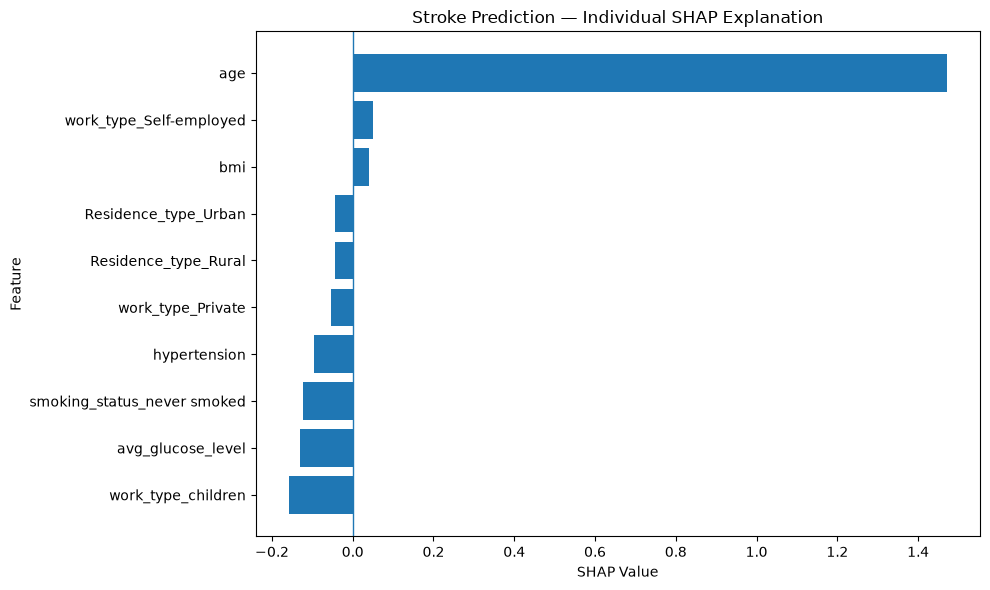

In [19]:
# ============================================================
# CELL 17 — INDIVIDUAL SHAP BAR PLOT
# ============================================================

plot_data = top_individual_features.sort_values(
    by="SHAP_Value"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["SHAP_Value"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("SHAP Value")
plt.ylabel("Feature")
plt.title("Stroke Prediction — Individual SHAP Explanation")

plt.tight_layout()
plt.show()

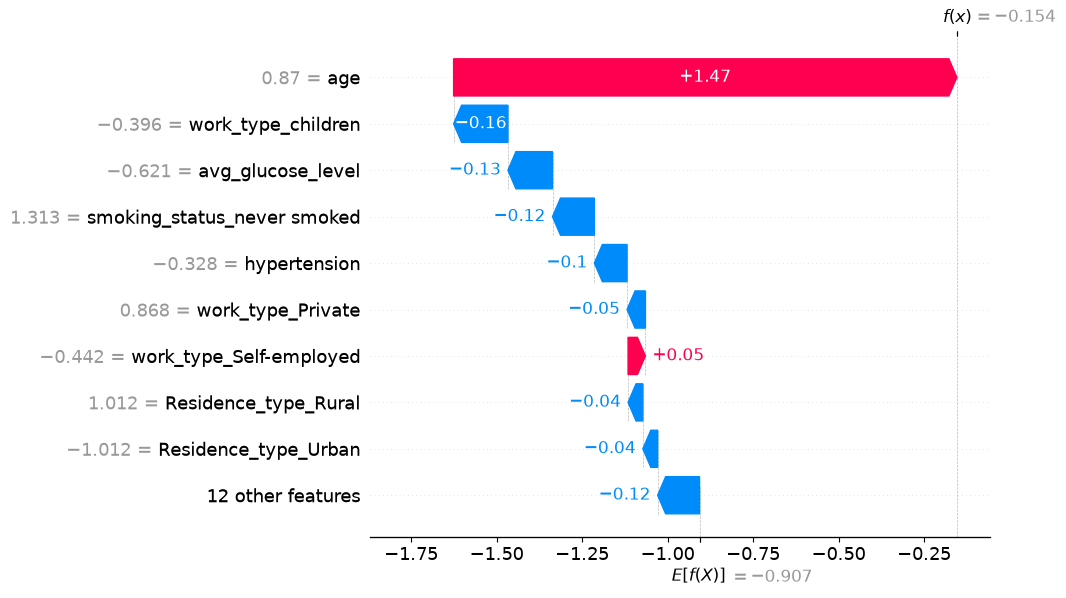

In [20]:
# ============================================================
# CELL 18 — SHAP WATERFALL PLOT
# ============================================================

shap.plots.waterfall(
    patient_explanation[0],
    max_display=10
)

In [21]:
# ============================================================
# CELL 19 — POSITIVE AND NEGATIVE CONTRIBUTORS
# ============================================================

positive_features = individual_shap[
    individual_shap["SHAP_Value"] > 0
].copy()

negative_features = individual_shap[
    individual_shap["SHAP_Value"] < 0
].copy()

positive_features = positive_features.sort_values(
    by="SHAP_Value",
    ascending=False
)

negative_features = negative_features.sort_values(
    by="SHAP_Value"
)

print("Features contributing toward Stroke prediction:")
display(
    positive_features.head(10)
)

print("\nFeatures contributing away from Stroke prediction:")
display(
    negative_features.head(10)
)

Features contributing toward Stroke prediction:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,age,0.869552,1.471695e+00,1.471695e+00
6,work_type_Self-employed,-0.441557,5.078311e-02,5.078311e-02
9,bmi,0.762101,4.142338e-02,4.142338e-02
16,work_type_Govt_job,-0.382600,1.988819e-02,1.988819e-02
17,smoking_status_Unknown,-0.662518,1.028330e-02,1.028330e-02
19,work_type_Never_worked,-0.056482,1.387467e-17,1.387467e-17
20,gender_Other,-0.015642,1.023906e-18,1.023906e-18



Features contributing away from Stroke prediction:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
1,work_type_children,-0.395933,-0.158807,0.158807
2,avg_glucose_level,-0.620654,-0.130363,0.130363
3,smoking_status_never smoked,1.312828,-0.122445,0.122445
4,hypertension,-0.327962,-0.095567,0.095567
5,work_type_Private,0.867757,-0.053742,0.053742
7,Residence_type_Rural,1.012307,-0.043258,0.043258
8,Residence_type_Urban,-1.012307,-0.043258,0.043258
10,gender_Female,-1.189390,-0.039624,0.039624
11,gender_Male,1.189990,-0.037424,0.037424
12,smoking_status_smokes,-0.425230,-0.032610,0.032610


In [22]:
# ============================================================
# CELL 20 — FINAL VERIFICATION
# ============================================================

print("=" * 70)
print("STROKE SHAP EXPLAINABILITY — VERIFICATION")
print("=" * 70)

print("Model:", type(model).__name__)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Features:", len(feature_names))
print("SHAP values shape:", shap_values.values.shape)

print("\nGlobal SHAP file:")
print(
    os.path.join(
        PROCESSED_DIR,
        "shap_feature_importance.csv"
    )
)

print("\nIndividual patient:")
print("Actual class:", actual_class)
print("Predicted class:", prediction)
print(
    "Stroke probability:",
    round(probability * 100, 2),
    "%"
)

print("\nNotebook 25 completed successfully.")

STROKE SHAP EXPLAINABILITY — VERIFICATION
Model: LogisticRegression
Training samples: 4088
Test samples: 1022
Features: 21
SHAP values shape: (1022, 21)

Global SHAP file:
d:\Explainable-AI-CDSS\datasets\processed\stroke\shap_feature_importance.csv

Individual patient:
Actual class: 0
Predicted class: 0
Stroke probability: 46.15 %

Notebook 25 completed successfully.
